<a href="https://colab.research.google.com/github/CarlosGer7/MetodosNum/blob/main/M%C3%A9todo_de_Neville.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Estudiante:** Leon Espinoza Carlos Germain  
**Materia:** Métodos Numéricos I  
**Fecha:** 20/11/2026

## Introducción
El método de Neville es una técnica de interpolación polinómica que evalúa el polinomio de interpolación en un punto específico \(x\) de manera iterativa. A diferencia del método de Lagrange, Neville permite agregar nuevos puntos de datos para obtener polinomios de mayor grado sin tener que recalcular todo desde cero.

## Formulación del Problema (Ejemplo 2, Pág. 89 - Burden)

Aproximar el valor de la función en \(x = 1.5\) utilizando los datos proporcionados en la Tabla 3.2 del libro de Burden.

**Datos de la tabla:**
* \(x_0 = 1.0 \implies f(x_0) = 0.7651977\)
* \(x_1 = 1.3 \implies f(x_1) = 0.6200860\)
* \(x_2 = 1.6 \implies f(x_2) = 0.4554022\)
* \(x_3 = 1.9 \implies f(x_3) = 0.2818186\)
* \(x_4 = 2.2 \implies f(x_4) = 0.1103623\)

Queremos encontrar \(f(1.5)\) mediante interpolación.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [12]:
def metodo_neville(x_eval, x_vals, y_vals):
    """
    Implementación del método de Neville para interpolación polinómica.
    """
    n = len(x_vals)

    # Creamos una matriz de ceros de tamaño n x n para guardar las aproximaciones
    Q = np.zeros((n, n))

    # Inicializamos la primera columna con los valores de f(x)
    for i in range(n):
        Q[i, 0] = y_vals[i]

    # Aplicamos la fórmula recursiva de Neville
    for j in range(1, n):
        for i in range(j, n):
            # Fórmula de Neville
            numerador = (x_eval - x_vals[i-j]) * Q[i, j-1] - (x_eval - x_vals[i]) * Q[i-1, j-1]
            denominador = x_vals[i] - x_vals[i-j]

            Q[i, j] = numerador / denominador

    return Q

# Datos
x_datos = [1.0, 1.3, 1.6, 1.9, 2.2]
y_datos = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]
x_interpolar = 1.5

# Ejecutamos la función
tabla_neville = metodo_neville(x_interpolar, x_datos, y_datos)

In [10]:
# Resultado Final
resultado = tabla_neville[-1, -1]
print(f"El valor aproximado de f({x_interpolar}) usando interpolación de Neville es: {resultado:.7f}")
print("-" * 60)

# Visualización de la tabla
tabla_formateada = np.where(tabla_neville == 0, np.nan, tabla_neville)

columnas = [f"Grado {i}" for i in range(len(x_datos))]
df_neville = pd.DataFrame(tabla_formateada, columns=columnas)

print("Tabla de Aproximaciones de Neville:")
display(df_neville.round(7))

El valor aproximado de f(1.5) usando interpolación de Neville es: 0.5118200
------------------------------------------------------------
Tabla de Aproximaciones de Neville:


,Grado 0,Grado 1,Grado 2,Grado 3,Grado 4
0,0.765198,NaN,NaN,NaN,NaN
1,0.620086,0.523345,NaN,NaN,NaN
2,0.455402,0.510297,0.512471,NaN,NaN
3,0.281819,0.513263,0.511286,0.511813,NaN
4,0.110362,0.510427,0.513736,0.511830,0.51182


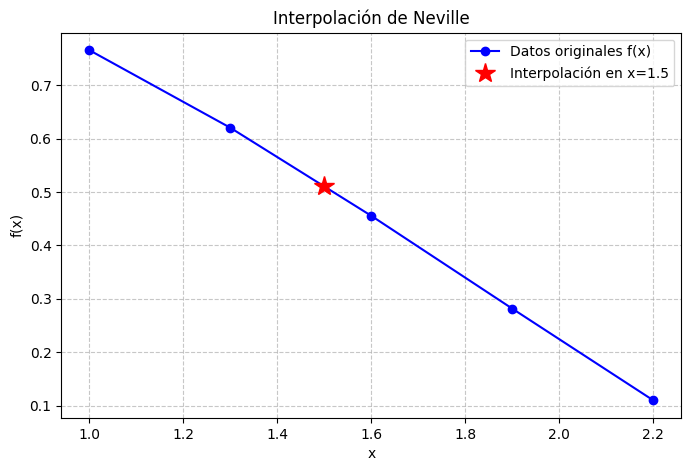

In [11]:
# Gráfica
plt.figure(figsize=(8, 5))
plt.plot(x_datos, y_datos, 'bo-', label='Datos originales f(x)')
plt.plot(x_interpolar, resultado, 'r*', markersize=15, label=f'Interpolación en x={x_interpolar}')
plt.title('Interpolación de Neville')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()

## <span style="color:green">Conclusión</span>

Al ejecutar el código, podemos observar que la tabla generada coincide perfectamente con la **Tabla 3.6** del libro de Burden.

* El polinomio lineal (grado 1) evaluado en 1.5 es \(0.5233449\).
* El polinomio de grado 4 (usando todos los puntos) nos da un valor final para \(f(1.5)\) de **\(0.5118200\)**.

Este método demuestra ser una herramienta poderosa para aproximar funciones, ya que permite visualizar cómo mejora la precisión a medida que se añaden más puntos (mayor grado del polinomio).